# 01 - Explore the Loghub 2k samples

A first look at the structured 2k samples for HDFS, BGL, OpenSSH and Apache.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_colwidth", 100)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
DOCS = ROOT / "docs"
DATASETS = ["HDFS", "BGL", "OpenSSH", "Apache"]


def load(name):
    # read as text so HDFS times keep their leading zeros
    return pd.read_csv(RAW / name / f"{name}_2k.log_structured.csv", dtype=str)


dfs = {name: load(name) for name in DATASETS}

## Timestamps

Each dataset stores time in different columns and formats, so each gets its own parser. OpenSSH logs have no year, so its times are shown without one.

In [2]:
def parse_times(name, df):
    if name == "HDFS":
        return pd.to_datetime(df["Date"] + df["Time"].str.zfill(6), format="%y%m%d%H%M%S")
    if name == "BGL":
        return pd.to_datetime(df["Time"], format="%Y-%m-%d-%H.%M.%S.%f")
    if name == "OpenSSH":
        return pd.to_datetime(df["Date"] + " " + df["Day"] + " " + df["Time"], format="%b %d %H:%M:%S")
    if name == "Apache":
        return pd.to_datetime(df["Time"], format="%a %b %d %H:%M:%S %Y")
    raise ValueError(name)


def fmt_time(name, ts):
    return ts.strftime("%b %d %H:%M:%S") if name == "OpenSSH" else ts.strftime("%Y-%m-%d %H:%M:%S")


def describe(name):
    df = dfs[name]
    times = parse_times(name, df)
    counts = df["EventId"].value_counts()
    top5 = (
        counts.head(5)
        .rename("Count")
        .to_frame()
        .join(df.drop_duplicates("EventId").set_index("EventId")["EventTemplate"])
    )

    print(f"Lines:   {len(df)}")
    print(f"Columns: {list(df.columns)}")
    print(f"Unique templates (EventId): {counts.size}")
    print(f"Time range: {fmt_time(name, times.min())}  ->  {fmt_time(name, times.max())}")
    display(top5)

    return {
        "dataset": name,
        "lines": len(df),
        "templates": counts.size,
        "start": fmt_time(name, times.min()),
        "end": fmt_time(name, times.max()),
        "anomaly_pct": float("nan"),
    }


summary = {}

## HDFS

In [3]:
summary["HDFS"] = describe("HDFS")

blocks = dfs["HDFS"]["Content"].str.findall(r"blk_-?\d+").explode().dropna()
print(f"Unique block IDs: {blocks.nunique()}")

Lines:   2000
Columns: ['LineId', 'Date', 'Time', 'Pid', 'Level', 'Component', 'Content', 'EventId', 'EventTemplate']
Unique templates (EventId): 14
Time range: 2008-11-09 20:36:15  ->  2008-11-11 10:20:17


,Count,EventTemplate
EventId,,
E6,314,BLOCK* NameSystem.addStoredBlock: blockMap updated: <*>:<*> is added to blk_<*> size <*>
E10,311,PacketResponder <*> for block blk_<*> terminating
E11,292,Received block blk_<*> of size <*> from /<*>
E13,292,Receiving block blk_<*> src: /<*>:<*> dest: /<*>:<*>
E9,263,Deleting block blk_<*> file /<*>/blk_<*>


Unique block IDs: 2200


## BGL

In [4]:
summary["BGL"] = describe("BGL")

is_normal = dfs["BGL"]["Label"] == "-"
label_counts = pd.DataFrame({
    "Count": [is_normal.sum(), (~is_normal).sum()],
    "Percent": [is_normal.mean() * 100, (~is_normal).mean() * 100],
}, index=["Normal", "Alert"]).round(2)
display(label_counts)

summary["BGL"]["anomaly_pct"] = round((~is_normal).mean() * 100, 2)

Lines:   2000
Columns: ['LineId', 'Label', 'Timestamp', 'Date', 'Node', 'Time', 'NodeRepeat', 'Type', 'Component', 'Level', 'Content', 'EventId', 'EventTemplate']
Unique templates (EventId): 120
Time range: 2005-06-03 15:42:50  ->  2006-01-03 07:13:09


,Count,EventTemplate
EventId,,
E67,721,generating core.<*>
E70,208,iar <*> dear <*>
E4,121,<*> floating point alignment exceptions
E3,109,<*> double-hummer alignment exceptions
E18,92,"CE sym <*>, at <*>, mask <*>"


,Count,Percent
Normal,1857,92.85
Alert,143,7.15


## OpenSSH

In [5]:
summary["OpenSSH"] = describe("OpenSSH")

Lines:   2000
Columns: ['LineId', 'Date', 'Day', 'Time', 'Component', 'Pid', 'Content', 'EventId', 'EventTemplate']
Unique templates (EventId): 27
Time range: Dec 10 06:55:46  ->  Dec 10 11:04:45


,Count,EventTemplate
EventId,,
E24,413,Received disconnect from <*>: <*>: Bye Bye [preauth]
E20,384,pam_unix(sshd:auth): authentication failure; logname= uid=<*> euid=<*> tty=ssh ruser= rhost=<*> ...
E9,383,Failed password for <*> from <*> port <*> ssh2
E21,135,pam_unix(sshd:auth): check pass; user unknown
E10,135,Failed password for invalid user <*> from <*> port <*> ssh2


## Apache

In [6]:
summary["Apache"] = describe("Apache")

Lines:   2000
Columns: ['LineId', 'Time', 'Level', 'Content', 'EventId', 'EventTemplate']
Unique templates (EventId): 6
Time range: 2005-12-04 04:47:44  ->  2005-12-05 19:15:57


,Count,EventTemplate
EventId,,
E1,836,jk2_init() Found child <*> in scoreboard slot <*>
E2,569,workerEnv.init() ok <*>
E3,539,mod_jk child workerEnv in error state <*>
E4,32,[client <*>] Directory index forbidden by rule: <*>
E5,12,jk2_init() Can't find child <*> in scoreboard


## Summary

`anomaly_pct` is only filled for BGL, the only 2k sample with line-level labels.

In [7]:
summary_df = pd.DataFrame(summary.values())
summary_df["time_range"] = summary_df["start"] + " -> " + summary_df["end"]
summary_df = summary_df[["dataset", "lines", "templates", "time_range", "anomaly_pct"]]

DOCS.mkdir(exist_ok=True)
summary_df.to_csv(DOCS / "dataset_summary.csv", index=False)
summary_df

,dataset,lines,templates,time_range,anomaly_pct
0,HDFS,2000,14,2008-11-09 20:36:15 -> 2008-11-11 10:20:17,NaN
1,BGL,2000,120,2005-06-03 15:42:50 -> 2006-01-03 07:13:09,7.15
2,OpenSSH,2000,27,Dec 10 06:55:46 -> Dec 10 11:04:45,NaN
3,Apache,2000,6,2005-12-04 04:47:44 -> 2005-12-05 19:15:57,NaN


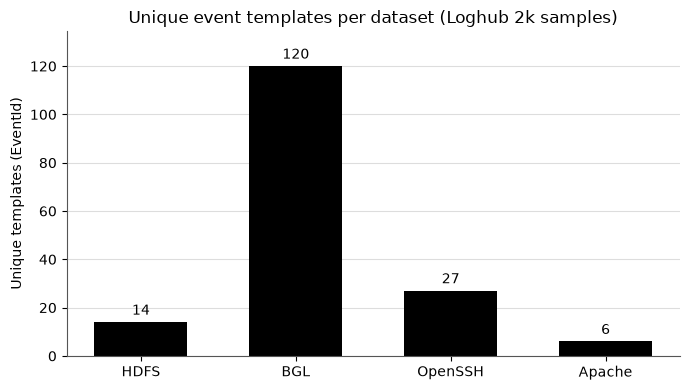

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(summary_df["dataset"], summary_df["templates"], color="black", width=0.6)
ax.bar_label(bars, padding=3, color="black")
ax.set_ylim(0, summary_df["templates"].max() * 1.12)

ax.set_title("Unique event templates per dataset (Loghub 2k samples)", color="black")
ax.set_ylabel("Unique templates (EventId)", color="black")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#555555")
ax.tick_params(colors="black")
ax.yaxis.grid(True, color="#dddddd", linewidth=0.8)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig(DOCS / "templates_per_dataset.png", dpi=150, facecolor="white")
plt.show()